# SSP($\lambda; t$) Playground


The spectrum of a Simple Stellar Population (SSP) changes a lot as its stars age. This is what allows us to look at the spectrum of a galaxy and guess the typical age of its stars, or, in more detail, its star formation history (SFH). To do this one needs a minimum level of familiarity with __how SSP spectra change with time.__

This notebook lets you play with SSP($\lambda$) as a function of $t$. Metallicity will be kept fixed throughout (default $Z = 0.02$, i.e, solar), as the goal here is to get a general sense of how SSP spectra evolve (but you'll be told how to change $Z$ if you really want to.)

<div class="alert alert-block alert-info">
<b>Here's an index of what you'll see below:</b>


- **(Fig 1)** Plot and examine SSP spectra for different ages
- **(Fig 2)** As above, but normalizing the spectra
- **(Fig 3)** An interactive plot to visualize the spectral evolution of SSPs
- **(Fig 4)** Plot the evolution of $l^{SSP}_\lambda(t)$ for a bunch of $\lambda$'s
- **(Fig 5)** Define an arbitrary color and see how it evolves with $t$
- **(Fig 6)** Define a couple of colours and plot evolution in a color-color-diagram
</div>

<div class="alert alert-block alert-warning">
<b>OBS:</b> SSP($\lambda,t$) is the same as the $l^{SSP}_\lambda(t,Z)$ used in our notes and the $\Lambda^{SSP}_\lambda(t,Z)$ used in the slides. If an $L_\lambda$ appears here or there, it's just sloppy notation.
</div>

## Initialization

In [18]:
# Initialization
%matplotlib inline
%matplotlib notebook
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import cycler
from matplotlib.widgets import Slider
from GeneralFunctionsLaPlata2024 import read_base_hdf5

# fontsize & etc...
_fs, _ls, _lw, _alpha = 10, 10, 2, 0.8
_figsize=(10, 6)

# To save or not to save figs
_saveFigs = True

## Read SSP($\lambda; t, Z$) models & pick those with solar metallicity

This notebook uses the BC03 models for a Chabrier IMF, Padova 1994 evolutionary tracks & STELIB spectral library. We focus on the models for $Z = 0.02 = Z_\odot$.

To plot results for a different $Z$, change _Z4plot_ to one of these values:
0.0001, 0.0004, 0.004, 0.008, 0.02, 0.05, but do **not** do this until you've gone through the whole set of exercises below!

In [27]:
# Read the default base.
basesDir = './'
baseFile = 'Base.bc03.Padova1994.chab.All'
t__j, _lix , Z__j, _lix, l__l, spec__lj = read_base_hdf5(basesDir + baseFile+'.h5')

# Pick the models for the chosen Z (default = solar)
Z4plot = 0.02
m__j = (Z__j == Z4plot)
t__j, spec__lj = t__j[m__j], spec__lj[:,m__j]
n_t, n_l = t__j.size, l__l.size
print('==> ', n_t, ' ages from ', t__j[0], 'to ', t__j[-1], 'yr')
print('==> ', n_l, ' wavelengths from ', l__l[0], 'to ', l__l[-1], 'A')
print()
print('==> Will plot spectra for Z = ', Z4plot)
print('    If you want another Z, change Z4plot to one of these options:', np.unique(Z__j))

(read_base_hdf5) reading  ./Base.bc03.Padova1994.chab.All.h5 ...
==>  221  ages from  0.0 to  20000000000.0 yr
==>  6900  wavelengths from  91.0 to  1600000.0 A

==> Will plot spectra for Z =  0.02
    If you want another Z, change Z4plot to one of these options: [0.0001 0.0004 0.004  0.008  0.02   0.05  ]


-------------------
# Fig 1 - SSP spectra for selected ages


Let's now finally plot SSP($\lambda; t$) for a bunch of ages $t$. Let's start by looking at spectra for the following list of ($\sim$ log-spaced) ages:
[1e6, 3e6, 1e7, 3e7, 1e8, 3e8, 1e9, 3e9, 1e10, 1.4e10] yr.

To change the list of ages in the plot play with the array *_tList* in the cell below.

OBS: The code will pick the ages in the *t__j* array closest to the ones in your *_tList* list.

In [4]:
#print(t__j)  # Uncomment to see the list of 221 ages in the models

In [30]:
# Select ages to plot & match them to those in the base
_tList = np.array([1e6, 3e6, 1e7, 3e7, 1e8, 3e8, 1e9, 3e9, 1e10, 1.4e10])
# _tList = t__j                        # uncomment to plot **all** ages! Very messy!
# _tList = np.geomspace(1e6,1e10,17)   # uncomment for a different set of ages.
_tListInBase = np.array([t__j[np.argmin(np.abs(t__j - _t))] for _t in _tList])

# set color cycle for different ages
_n_colors = np.unique(_tListInBase).size
_color = plt.cm.jet(np.linspace(0, 1, _n_colors))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)

# the plot
# fig = plt.figure(1, figsize=_figsize)
fig = plt.figure(1)  # Uncomment in case the plot appears cropped! Pinche jupyter!
plt.clf()
for _j in range(len(_tListInBase)):
    plt.plot(l__l,spec__lj[:,t__j == _tListInBase[_j]], alpha=_alpha, lw=_lw, \
        label=str(f'{_tListInBase[_j]/1e9:6.3f}')+' Gyr')

# plot limits
xLow, xUpp = 0, 12999
yLow, yUpp = 1e-7, 1
plt.xlim(xLow,xUpp)
plt.ylim(yLow,yUpp)

# etc
plt.yscale('log')
plt.xlabel(r'$\lambda\,[\AA]$', fontsize=2*_fs)
plt.ylabel(r'$l^{SSP}_\lambda \,\,\, [L_\odot \,\AA^{-1} \, / \, M_\odot]$', fontsize=2*_fs)
plt.grid(True)
plt.title(r'SSP($\lambda, t, Z=$' + str(Z4plot) + ') for ' + str(len(_tListInBase)) + ' ages', fontsize=2*_fs)
if len(_tListInBase) < 20:
    plt.legend(loc=1)

if _saveFigs:
    plt.savefig('fig_LaPlata02_1.png')

<div class="alert alert-block alert-info">
<b>Tip:</b> Press 'l' over the plot-window to see things linearly in the y-scale. Log-scales are useful but they also fool us! [If this does not work then comment the plt.yscale('log') line in the cell above.]</div>


<div class="alert alert-block alert-warning">
    
- Did you notice that the spectral sampling $\Delta \lambda$ varies? (Look for instance, around $\lambda \sim 3300$ or $\sim 9300$ A). Can you guess why?

- What is $M_\odot^{-1}$ doing in the y-axis units?</div>

### Questions:


- (1.1) Pick a wavelength, say $\lambda = 2000$ A. By how many orders of magnitude does $L_\lambda$ vary from the minimum to the maximum age in the plot? Do the same estimate for, say, $\lambda = 5500$ and 10000 A.

- (1.2) Try to identify *(at least some of)* the following features:
    - Lyman-break @912 A
    - The CaII H&K lines @3969, 3934 A
    - The MgI lines @5167, 5172, 5183 A
    - The Fe lines @5270, 5335 A
    - The CaII triplet @8498, 8542, 8662 A
    - The NaI D doublet @5891, 5896 A
    - The first members of the Balmer series @ 6563 (H$\alpha$), 4861 (H$\beta$), 4340 (H$\gamma$), and 4102 (H$\delta$).
    - Higher order Balmer lines (H$\epsilon$, H8, H9, $\ldots$)
    - OBS: Some of these features will be very weak (or absent!) for some ages - which is precisely why they are useful age-indicators!

-------------------
# Fig 2 - Normalized spectra (for the same selected ages)

It is often useful to scale all spectra to a unit flux in a arbitrary (but convenient) wavelength or wavelength interval. The cell below starts by defining a normalization window centered at $\lambda = \lambda_N = 5635$ A and of width $\Delta \lambda_N = 90$ A (an arbitrary choice which you may change). Each SSP spectrum is then plotted after dividing it by the mean $l_\lambda$ in the $\lambda_N - \Delta \lambda_N/2 < \lambda < \lambda_N + \Delta \lambda_N/2$ range.

Why is this useful? Normalization removes the amplitude of the spectra, allowing one to compare their shapes more clearly.

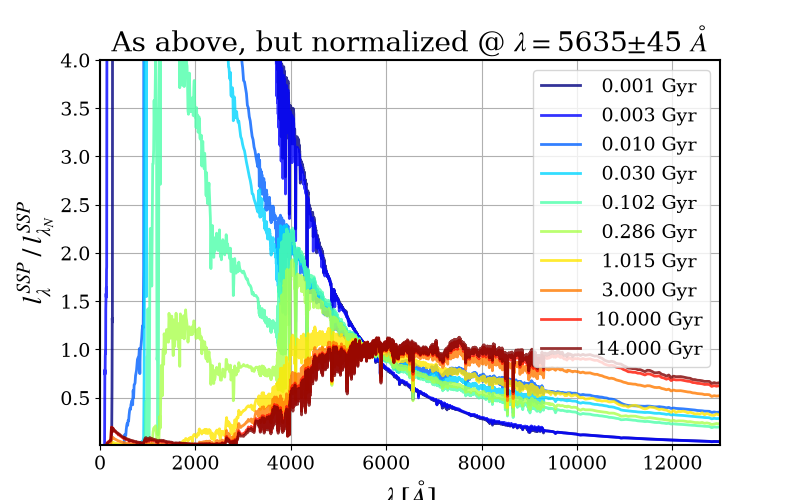

In [9]:
# Def normalization window
lNorm, dlNorm = 5635, 90

# the plot
plt.figure(2)
# plt.clf()
for _j in range(len(_tListInBase)):
    _y = spec__lj[:,t__j == _tListInBase[_j]]
    _yNorm = _y[np.abs(l__l - lNorm) <= dlNorm/2].mean()
    _y /= _yNorm
    plt.plot(l__l,_y, alpha=_alpha, lw=_lw, \
        label=str(f'{_tListInBase[_j]/1e9:6.3f}')+' Gyr')

# plot limits
xLow, xUpp = 0, 12999
yLow, yUpp = 1e-2, 4
plt.xlim(xLow,xUpp)
plt.ylim(yLow,yUpp)

plt.xlabel(r'$\lambda\,[\AA]$', fontsize=2*_fs)
plt.ylabel(r'$l^{SSP}_\lambda \, / \, l^{SSP}_{\lambda_N}$', fontsize=2*_fs)
plt.grid(True)
plt.title(r'As above, but normalized @ $\lambda =$'+ str(int(lNorm)) + r'$\pm$' + str(int(dlNorm/2)) + r' $\AA$', fontsize=2*_fs)
if len(_tListInBase) < 20:
    plt.legend(loc=1)
# if _saveFigs: # for save the figure, but do it after
#    plt.savefig('fig_LaPlata02_2.png')

<div class="alert alert-block alert-info">
<b>Tip:</b> Press 'l' over the plot to toggle linear/log scales for the y-axis.</div>


<div class="alert alert-block alert-warning">
You may change $\lambda_N$ and/or $\Delta\lambda_N$ in the cell above (lNorm, dlNorm = ...) and rerun it.
</div>

-------------------
# Fig 3 - An interactive plot

Here's another way of visualizing the evolution of SSP($\lambda$). Slide the $\log t$ ruler to see evolution on a "day-by-day" basis.

The $\lambda$-limits are set by the *xLow* & *xUpp* variables.
*xLow, xUpp = 3600, 5400* by default, but you'll be asked to change this.


<div class="alert alert-block alert-danger">
<b>BEWARE:</b> This cell may crash your jupyter notebook!! At least it did so on the INAOE machines with less RAM...
</div>

0

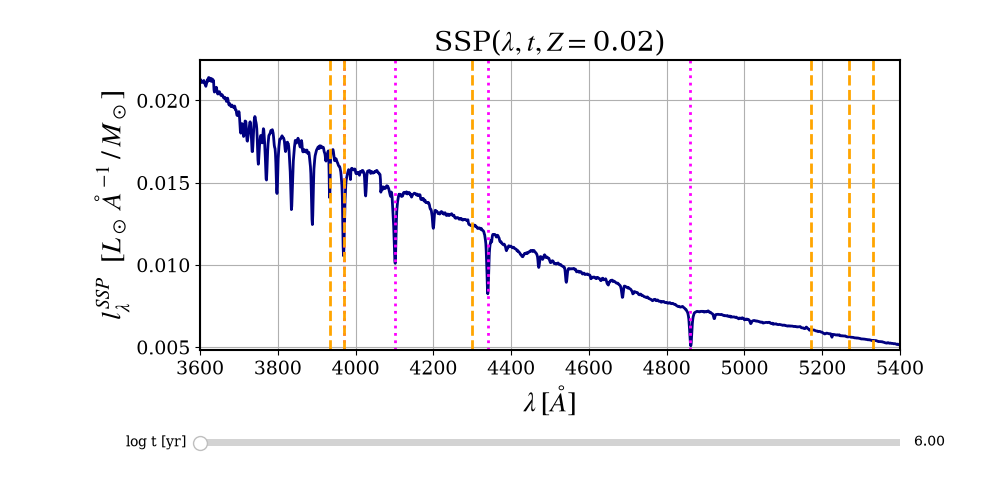

In [11]:
# set x-limits
xLow, xUpp = 3600, 5400
# xLow, xUpp = 4800, 5400  # for question 3.1
# xLow, xUpp = 3700, 4200  # for question 3.2
# xLow, xUpp =  100, 1500  # for question 3.3

mark_some_selected_lines = True

# etc
autoscale_y = True
showzero_y = True
logscale_y = False
yLow, yUpp = 1e-7, 1

logt__j = np.log10(t__j + 1) # silly trick to avoid log(0)!
j0 = 0; logt0 = logt__j[j0]
x, y = l__l, spec__lj[:,j0]
if autoscale_y:
    _mask__l = (l__l > xLow) & (l__l< xUpp)
    yLow, yUpp = 0.95 * y[_mask__l].min(), 1.05 * y[_mask__l].max()

# Slider plot...
fig = plt.figure(3, figsize=(10, 5)) # OJO: The fig sometimes appears too big ... fix it here!
plt.clf()
plt.subplots_adjust(bottom=0.3,left=0.2,right=0.9)
ax = fig.subplots()

p, = ax.plot(x,y)
plt.xlim(xLow,xUpp)
plt.ylim(yLow,yUpp)
if logscale_y:
    plt.yscale('log')
plt.xlabel(r'$\lambda\,[\AA]$', fontsize=2*_fs)
plt.ylabel(r'$l^{SSP}_\lambda \,\,\, [L_\odot \,\AA^{-1} \, / \, M_\odot]$', fontsize=2*_fs)
plt.grid(True)
_s = str(f'{_tListInBase[_j]/1e9:6.3f}')+' Gyr'
plt.title(r'SSP($\lambda, t, Z=$' + str(Z4plot) + ')', fontsize=2*_fs)

# Add/remove lines to the lists as you wish!
if mark_some_selected_lines:
    _linesBalmer = [3970, 4102, 4340, 4861]
    [plt.axvline(x=_l, color='magenta', linestyle=':') for _l in _linesBalmer]
    _linesMetals = [3934, 3969, 4300, 5172, 5270, 5330]
    [plt.axvline(x=_l, color='orange', linestyle='--') for _l in _linesMetals]
    plt.axvline(x=912, color='red', linestyle='--') # Lyman break 912 A = 13.6 eV


# Iteractive logt-slider...
ax_slide_logt = plt.axes([0.2, 0.1, 0.7, 0.03])
s_logt = Slider(ax_slide_logt, 'log t [yr]', 6, 10.15, valinit=logt0, valstep=0.01)

def update_logt(logt_slider):
    _j = np.argmin(np.abs(logt__j - logt_slider))
    # print('(update_logt)', logt_slider, _j,logt__j[_j])
    p.set_ydata(spec__lj[:,_j])
    if autoscale_y:
        _mask__l = (l__l > ax.get_xlim()[0]) & (l__l< ax.get_xlim()[1])
        _y = spec__lj[_mask__l,_j]
        _yLow, _yUpp = 0.95 * _y.min(), 1.05 * _y.max()
        if showzero_y:
            _yLow = 0
        # print('(update_logt)', xLow,xUpp, _yLow, _yUpp)
        ax.set_ylim(_yLow, _yUpp)
        plt.axvline(x=5330)
        _s = str(f'{10**logt_slider/1e9:6.3f}') +' Gyr'
        ax.set_title(r'SSP($\lambda, t =$ ' + _s + ',   $Z=$' + str(Z4plot) + ')', fontsize=2*_fs)

    fig.canvas.draw()

s_logt.on_changed(update_logt)

<div class="alert alert-block alert-info">
    <b> Tip:</b> Change <i>xLow</i> & <i>xUpp</i> (or use the zoom/pan buttons) to modify the $\lambda$-limits.
</div>

### Questions

- (3.1) Zoom in on the region from $\sim 4800$ to 5400 A and re-play the "movie". At the blue end the main feature is H$\beta$ (@4861), while on the red end you should see the MgI lines (@5167, 5173, 5184), but their evolution is very different! Describe the time-evolution of these lines (ie., when they go upp, when they go down, etc.)

- (3.2) Now zoom in on the $\sim 3700$ to 4200 A range and repeat the exercise above. This is a messy region! Focus on the CaII K line @ 3934 on the blue side and on H$\delta$ 4102 A on the red.

- (3.3) Finaly, zoom in on the H-ionizing range, say, from *xLow* = 100 to *xUpp* = 1500 A. Remember that $\lambda < 912$ A photons have $h\nu > 13.6$ eV, and thus can ionize hydrogen. The number of ionizing photons produced per unit time is simply the integral over $\lambda$ of $L_\lambda / h\nu = L_\lambda \lambda / h c$ from $\lambda = 0$ to 912 A, i.e., $\int_0^{912 A} (L_\lambda \lambda / h c) d\lambda$. We'll compute this properly in due course, but for now it suffices to evaluate this as $\propto$ to the area under the $l_\lambda^{SSP}$ spectrum for $\lambda < 912$ A. Replay the "movie" for the new *xLow* = 100 to *xUpp* = 1500 A and describe your **visual** impressions on how this area changes with age.

- (3.4) Two lines overlap at 3969 & 3970 A. Do you know which are them?

<div class="alert alert-block alert-info">
<b> Tip:</b> It is useful to set <i>mark_some_selected_lines</i> = True to mark some special wavelengths with a vertical line. (Feel free to add more marks of your liking.)
</div>

-------------------
# Fig 4 - Evolution @ some selected $\lambda$'s

The plots above all have $\lambda$ in the $x$-axis. Age is shown either as a color (Figs 1 & 2) or a slide-bar (Fig 3). Since we want to see how things change with time, it is instructive to plot things as a functon of $t$.

The cell below plots $l^{SSP}_\lambda$ as a function of $\log t$ for a few selected wavelengths. The list of chosen $\lambda$'s is set by the *_lList* array below. The script find the closest $\lambda$ in the models and uses it instead.

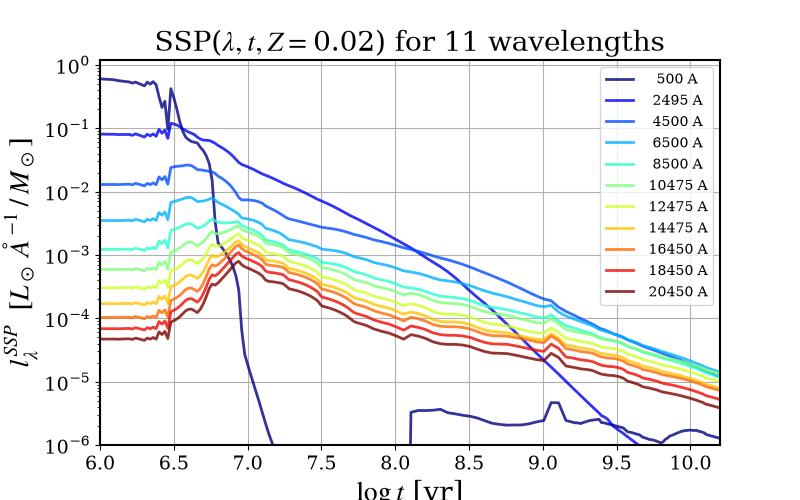

In [12]:
# Define a list of lambdas and match the to those in the models
_lList = np.arange(500,22500,2000)
_lListInBase = np.array([l__l[np.argmin(np.abs(l__l - _l))] for _l in _lList])

# set color cycle for different lambdas
_n_colors = np.unique(_lListInBase).size
_color = plt.cm.jet(np.linspace(0, 1, _n_colors))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)

# the plot
# fig = plt.figure(4, figsize=(10, 6))
fig = plt.figure(4)
plt.clf()
_fs, _lw, _alpha = 10, 2, 0.8
for _l in range(len(_lListInBase)):
    _ind_l = np.argwhere(l__l == _lListInBase[_l])[0][0]
    plt.plot(logt__j,spec__lj[_ind_l,:], alpha=_alpha, lw=_lw, \
         label=str(f'{_lListInBase[_l]:6.0f}')+' A')

logtLow, logtUpp = 6.0, 10.2
yLow, yUpp = 1e-6, 1.2
plt.xlim(logtLow, logtUpp)
plt.ylim(yLow,yUpp)
plt.yscale('log')
plt.xlabel(r'$\log t$ [yr]', fontsize=2*_fs)
plt.ylabel(r'$l^{SSP}_\lambda \,\,\, [L_\odot \,\AA^{-1} \, / \, M_\odot]$', fontsize=2*_fs)
plt.grid(True)
plt.title(r'SSP($\lambda, t, Z=$' + str(Z4plot) + ') for ' + str(len(_lListInBase)) + ' wavelengths', fontsize=2*_fs)
if len(_lListInBase) < 20:
    plt.legend(loc=1, fontsize=_fs)
plt.figure(4)
if _saveFigs:
    plt.savefig('fig_LaPlata02_4.png')

<div class="alert alert-block alert-info">
<b>Tip:</b> Press 'l' over the plot to toggle linear/log scales for the y-axis.</div>


### Questions

- Make sure you turn the log scale on & off to have a real feeling of the y-scale!
- (4.1) Why is it that shorter $\lambda$'s change so much more than longer ones?
- Ask Sandro what happens around 3 Myr ($\log t \sim 6.5$)! What happens in massive stars that make them shine brigther around this time?



**For the pynerds:** Can you think of a way of plotting the evolution for all $\lambda$'s against $t$ time so that the plot is minimally comprehensible?


<div class="alert alert-block alert-warning">
<b>OBS:</b>
The time integral of this curves, $\Phi^{SSP}(\lambda,T) = \int_0^T l^{SSP}_\lambda(t) dt$,  will appear later in our exercises when we talk about SFR indicators.
</div>

# 

-------------------
# Fig 5 - Color evolution

From the above experiments you should have noticed that an SSP __gets redder as it ages.__ (If you didn't then go back and start over!) This is the basic reason why (barring dust-related effects) when can confidently say that a red galaxy has (on average) older stars than a blue one. Ellipticals are redder than spirals, so their stellar populations must also be older. Bulges are also redder than discs, so they must also be older.

Let's try to make this more quantitative. When we say a galaxy is red what we mean is that fluxes on longer (redder) wavelengths are larger than those in shorter (bluer) $\lambda$'s. __Color is a comparative thing.__
One could define a color as the __ratio__ $F_{\lambda_2} / F_{\lambda_1}$ between the flux (or luminosity) densities at two specific wavelengths $\lambda_2$ and $\lambda_1$, but it is much more sensible to talk about __intervals__ around $\lambda_1$ and $\lambda_2$.

Let us then define $F_1$ as the mean flux in a __band__ covering the $\lambda_1 \pm \Delta \lambda_1/2$ interval, and likewise for $F_2$ (the mean flux over $\lambda_2 \pm \Delta \lambda_2/2$).
The ratio $F_2/F_1$ gives a quantitative (and observationaly useful) measure of the colour of galaxy. Astronomical convention dictates that $\lambda_2 > \lambda_1$ when talking about colours, so that a larger value of $F_{\lambda_2} / F_{\lambda_1}$ means redder and vice-versa.


The cell below computes the value of $F_1$ and $F_2$ for bands 1 and 2, whose $\lambda_1$, $\Delta\lambda_1$, $\lambda_2$, and $\Delta\lambda_2$ are defined in the __first line__. The default values are

- *l1, dl1 = 3800, 100 ; l2, dl2 = 4100, 100*

i.e., band#1 covers from 3850 to 3950 A, while band#2 spans from 4000 to 4100 A.
These seemingly arbitrary choices approximately trace the so called "4000 A break". As should be obvious from the plot generated below, this index is a good indicator of the age, as it grows nearly monotonically as $t$ increases.

In [15]:
l1, dl1 = 3900, 100 ; l2, dl2 = 4050, 100      # equivalent to Dn4000...
# l1, dl1 = 2267,  500 ; l2, dl2 = 6258, 1465  # equivalent to NUV & r
# l1, dl1 = 4751, 1050 ; l2, dl2 = 6258, 1465  # equivalent to g & r


# compute mean fluxes in bands 1 & 2, and their ratio
m1 = np.abs(l__l - l1) <= dl1 / 2
m2 = np.abs(l__l - l2) <= dl2 / 2
F1__j = spec__lj[m1,:].mean(axis=0)
F2__j = spec__lj[m2,:].mean(axis=0)
F2F1__j = F2__j / F1__j

# plot the time-evolution of bands 1 & 2 & their ratio
# fig = plt.figure(5, figsize=(10, 6))
fig = plt.figure(5)
plt.clf()
xLow, xUpp = 0, 12999
yLow, yUpp = 1e-7, 1

logt__j = np.log10(t__j + 1)

plt.subplot(211)
plt.plot(logt__j, F1__j, 'b', label='band 1')
plt.plot(logt__j, F2__j, 'r', label='band 2')
plt.grid()
plt.legend()
logtLow, logtUpp = 6, 10.2
plt.xlim(logtLow, logtUpp)
plt.xlabel('log t [yr]')
plt.ylabel('Band fluxes')

plt.subplot(212)
plt.plot(logt__j, F2F1__j, 'k', label='ratio')
plt.grid()
plt.xlim(logtLow, logtUpp)
plt.xlabel('log t [yr]')
plt.ylabel('F2/F1 "colour"')

_s = r'band#1: ' + str(int(l1-dl1/2)) + r'$ < \lambda <$' + str(int(l1+dl1/2)) +  '  |  band#2: ' + str(int(l2-dl2/2)) + r'$ < \lambda <$' + str(int(l2+dl2/2))
plt.suptitle(_s, fontsize=2*_fs)
#plt.tight_layout()

if _saveFigs:
    plt.savefig('fig_LaPlata02_5.png')

<div class="alert alert-block alert-info">
<b>Tip:</b> Press 'l' to toggle linear/log scales for the y-axis.</div>

<div class="alert alert-block alert-success">
<b>Note:</b> The mean flux over a $\lambda$-band is analogous to what a photometric observation with a square filter would give you. We'll deal with photometry for real filters elsewhere.
</div>

### Questions:
- (5.1) Suppose that (for the default band definitions) you measure $F_2/F_1 = 1.8 \pm 0.1$. Estimate (visually!) what would be the log age of the system and is uncertainty?
- (5.2) Repeat the estimation for $F_2/F_1 = 0.9 \pm 0.1$.

Try other definitions of bands 1 & 2 and re-run the cell. Here are some suggestions:

- (5.3) l1, dl1 = 2267,  500 ; l2, dl2 = 6258, 1465    $\sim$ equivalent to NUV & r bands
- (5.4) l1, dl1 = 4751, 1050 ; l2, dl2 = 6258, 1465    $\sim$ equivalent to g & r bands




<Figure size 800x500 with 0 Axes>

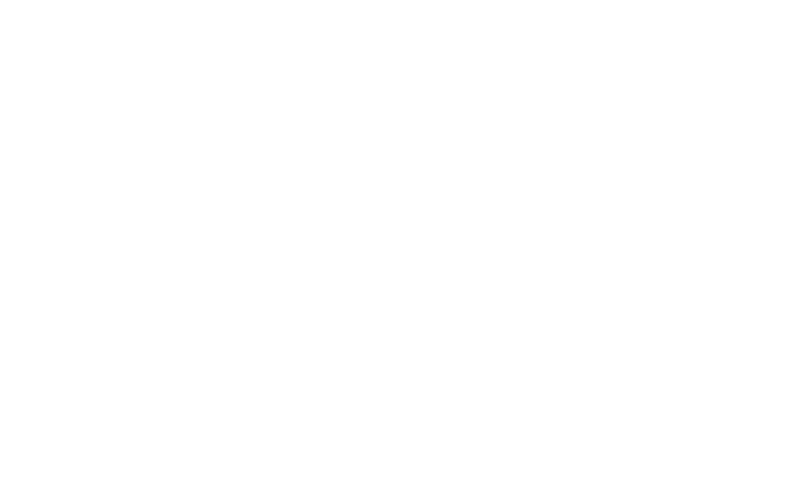

In [14]:
plt.figure(7)

-------------------
# Fig 6 - Evolution in a "color-color" diagram

Color-color diagrams are a useful tool in astronomy. Let's expand upon the previous plot and define four bands and two colours: $F_2/F_1$ (as above) and $F_3/F_4$. Plotting these two ratios against each other for SSPs of all ages is an crude way of mimicking what observers do with actual galaxy data.

The cell bellow defines the following 4 bands:
- l1, dl1 = 3900, 100 ; l2, dl2 = 4050, 100    $\sim$ equivalent to $D_n(4000)$
- l3, dl3 = 2267,  500 ; l4, dl4 = 6258, 1465  $\sim$ equivalent to NUV (GALEX) & r (SDSS) bands

Bands 1 & 2 are such that the resulting $F_2/F_1$ ratio gives the so called 4000 A break index, $D_n(4000)$, an excellent age indicator. Bands 3 & 4 are such that $F_4/F_3$ is analogous to the NUV - r colour. Both are widely used in the literature. The $F_4/F_3$ x $F_2/F_1$ plots below (both in linear and log versions) are coloured by the log age of the SSP.

Band 1: l1= 3900 dl1= 100
Band 2: l2= 4050 dl2= 100
Band 3: l3= 2267 dl3= 500
Band 4: l4= 6258 dl4= 1465


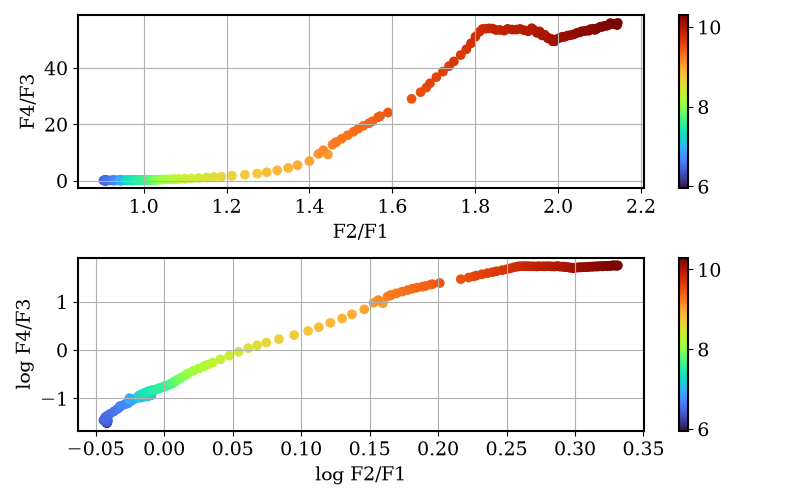

In [16]:
# Define bands 1, 2 & 3, 4
l1, dl1 = 3900, 100 ; l2, dl2 = 4050, 100    # equivalent to Dn4000...
l3, dl3 = 2267,  500 ; l4, dl4 = 6258, 1465  # equivalent to NUV & r


# compute mean fluxes in bands 1, 2, 3 & 4 & the F2/F1 & F4/F3 colors
m1 = np.abs(l__l - l1) <= dl1 / 2 ; F1__j = spec__lj[m1,:].mean(axis=0)
m2 = np.abs(l__l - l2) <= dl2 / 2 ; F2__j = spec__lj[m2,:].mean(axis=0)
m3 = np.abs(l__l - l3) <= dl3 / 2 ; F3__j = spec__lj[m3,:].mean(axis=0)
m4 = np.abs(l__l - l4) <= dl4 / 2 ; F4__j = spec__lj[m4,:].mean(axis=0)
F2F1__j = F2__j / F1__j
F4F3__j = F4__j / F3__j

# plot the time-evolution of bands 1 & 2 & their ratio
# fig = plt.figure(6, figsize=(10, 6))
fig = plt.figure(6)
plt.clf()

_m = logt__j >= 5.9  # plot only ages > 1 Myr
x, y, z = F2F1__j[_m], F4F3__j[_m], logt__j[_m]
plt.subplot(211)
plt.scatter(x, y, c=z, cmap='turbo') ; plt.colorbar()
plt.xlabel('F2/F1') ; plt.ylabel('F4/F3') ; plt.grid()

plt.subplot(212)
plt.scatter(np.log10(x), np.log10(y), c=z, cmap='turbo') ; plt.colorbar()
plt.xlabel('log F2/F1') ; plt.ylabel('log F4/F3') ; plt.grid()
plt.tight_layout()

if _saveFigs:
    plt.savefig('fig_LaPlata02_6.png')

print('Band 1: l1=',l1, 'dl1=', dl1)
print('Band 2: l2=',l2, 'dl2=', dl2)
print('Band 3: l3=',l3, 'dl3=', dl3)
print('Band 4: l4=',l4, 'dl4=', dl4)

The color bar maps the $\log t$ (in yr). Clearly, the location of a given galaxy in this plot already gives a decent $1^{\rm st}$ order estimate of what is the typical age of its stars.


### Questions:
- (6.1) Which of the two colors is more suceptible to reddening by dust?

<div class="alert alert-block alert-danger">
<b>Note:</b> Though these plots are conceptually correct, astronomers define coulours in terms of magnitudes, not fluxes nor luminosities ... (more on this in a later notebook).
</div>

------
# Done? Then explore what happens for other metallicities!

All you've done above is for $Z = Z_\odot$. To redo everything for a different $Z$, change _Z4plot_ in the 2nd cell to one of these values: 0.0001, 0.0004, 0.004, 0.008, 0.02, 0.05

------
# Want more? Really? The re-do everything for a different IMF!

Go to the 2nd cell and change the IMF by setting (assuming you have the file!)

_baseFile_ = 'Base.bc03.Padova1994.salp.All'

The age & metallicity grid is the same. But the $l^{SSP}_\lambda(t,Z)$ are different from those obtained with the Chabrier IMF used as default in this notebook! Too different? Just a litte? Diferent in shape or form or both?
Well, if you really want more then DIY ;-)